In [5]:
# Suppress specific ISLP ModelSpec deprecation warnings
import warnings

warnings.filterwarnings("ignore", message="ModelSpec will move")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [6]:
# Load the Carseats dataset
carseats = load_data("Carseats")

# --- Part (a) & (b): Fit Full Model ---
design_full = MS(["Price", "Urban", "US"], intercept=True)
X_full = design_full.fit_transform(carseats)
y = carseats["Sales"]

model_full = sm.OLS(y, X_full).fit()
print("=== FULL MODEL SUMMARY ===")
print(model_full.summary())

# --- Part (e): Fit Reduced Model (dropping 'Urban' because p = 0.936) ---
design_small = MS(["Price", "US"], intercept=True)
X_small = design_small.fit_transform(carseats)

model_small = sm.OLS(y, X_small).fit()
print("\n=== REDUCED MODEL SUMMARY ===")
print(model_small.summary())

# --- Part (g): 95% Confidence Intervals for Reduced Model ---
print("\n=== 95% CONFIDENCE INTERVALS ===")
print(model_small.conf_int(alpha=0.05))

# --- Part (h): Outliers and High Leverage Diagnostics ---
influence = model_small.get_influence()
studentized_resid = influence.resid_studentized_external
leverage = influence.hat_matrix_diag

n = len(carseats)
p = X_small.shape[1] - 1  # Number of predictors (2)
leverage_threshold = 2 * (p + 1) / n

print(f"\nOutliers (|Studentized Residual| > 3): {np.sum(np.abs(studentized_resid) > 3)}")
print(f"High Leverage threshold: {leverage_threshold:.4f}")
print(f"Observations exceeding leverage threshold: {np.sum(leverage > leverage_threshold)}")

=== FULL MODEL SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.234
Method:                 Least Squares   F-statistic:                     41.52
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           2.39e-23
Time:                        01:05:32   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1863.
Df Residuals:                     396   BIC:                             1879.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     13.0435    

=== MULTICOLLINEARITY (VIF CHECK) ===
          Feature         VIF
0           const    1.000000
1          Length   40.945763
2        Diameter   42.379841
3          Height    3.581369
4    Whole weight  109.768710
5  Shucked weight   28.550546
6  Viscera weight   17.445012
7    Shell weight   21.263272
8           Sex_I    1.983709
9           Sex_M    1.398273

--- Linear Regression Performance ---
R2 Score: 0.5482
RMSE: 2.2116

--- Random Forest Performance ---
R2 Score: 0.5282
RMSE: 2.2601


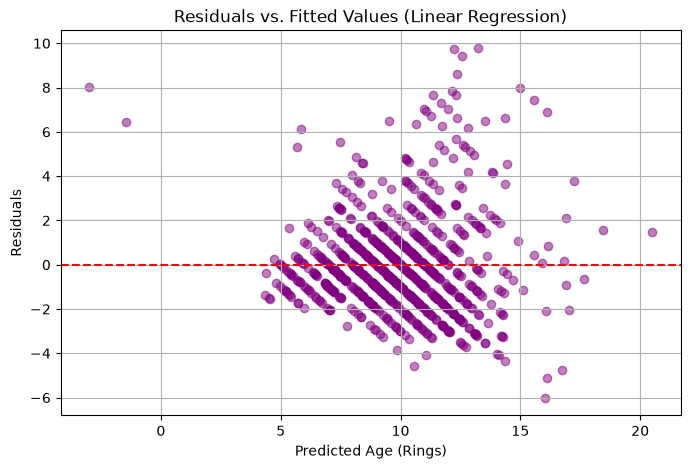

In [8]:
import warnings

warnings.filterwarnings("ignore", message="ModelSpec will move")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Load Abalone dataset directly from the official UCI repository URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
column_names = [
    "Sex",
    "Length",
    "Diameter",
    "Height",
    "Whole weight",
    "Shucked weight",
    "Viscera weight",
    "Shell weight",
    "Rings",
]
df = pd.read_csv(url, header=None, names=column_names)

# 2. Preprocessing: One-hot encode the categorical 'Sex' column
X = pd.get_dummies(df.drop("Rings", axis=1), drop_first=True)
y = df["Rings"]

# Split data into training and local test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Investigating Regression Assumptions: Multicollinearity (VIF)
X_vif = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])
]
print("=== MULTICOLLINEARITY (VIF CHECK) ===")
print(vif_data)

# 4. Model 1: Multiple Linear Regression Baseline
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

print("\n--- Linear Regression Performance ---")
print(f"R2 Score: {r2_score(y_test, y_pred_lr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}")

# 5. Model 2: Random Forest Regressor (Non-parametric alternative)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("\n--- Random Forest Performance ---")
print(f"R2 Score: {r2_score(y_test, y_pred_rf):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")

# 6. Residual Analysis Plot
residuals = y_test - y_pred_lr
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_lr, residuals, alpha=0.5, color="purple")
plt.axhline(y=0, color="red", linestyle="--")
plt.title("Residuals vs. Fitted Values (Linear Regression)")
plt.xlabel("Predicted Age (Rings)")
plt.ylabel("Residuals")
plt.grid(True)
plt.show()

Durbin-Watson Statistic: 2.0180


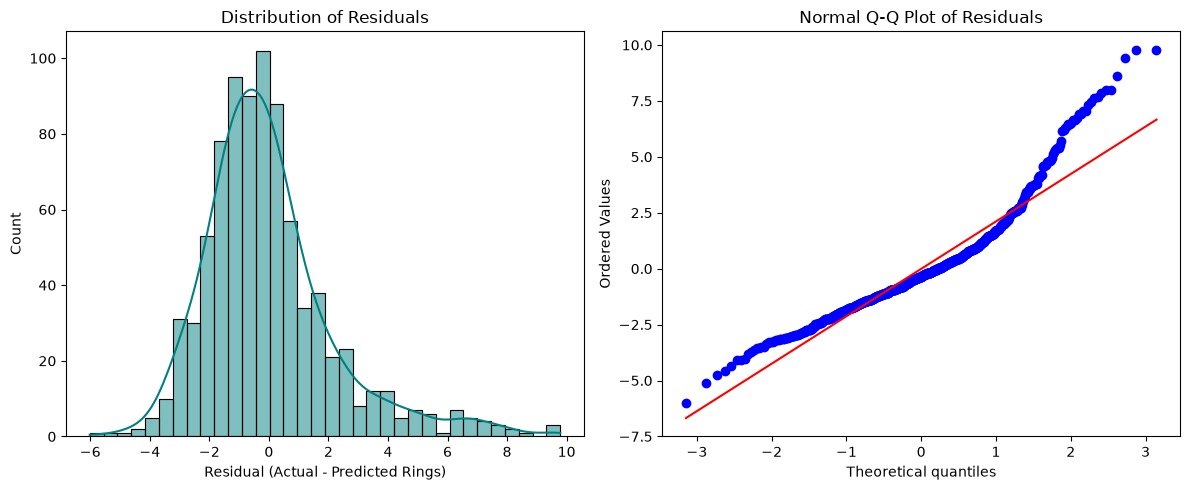

In [9]:
import scipy.stats as stats
from statsmodels.stats.stattools import durbin_watson

# Calculate residuals from your Linear Regression test predictions
residuals = y_test - y_pred_lr

# 1. Independence of Errors: Durbin-Watson Test
# Values close to 2.0 indicate no autocorrelation (independent errors)
dw_stat = durbin_watson(residuals)
print(f"Durbin-Watson Statistic: {dw_stat:.4f}")

# 2. Distribution of Residuals: Q-Q Plot & Histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram with KDE
sns.histplot(residuals, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residual (Actual - Predicted Rings)")

# Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()